# CS4085 Deep Learning — Lab 3: Weight Initialization

**Effat University · College of Engineering · Computer Science**

Before a neural network can learn, every weight needs a starting value. That choice matters more than it looks: a bad start can stop learning completely, or make it very slow.

In this lab you will train the **same** 3-layer network three times, changing only the initialization:

1. **Zeros** — every weight starts at 0
2. **Large random** — weights drawn from a normal distribution × 10
3. **He initialization** — weights drawn from a normal distribution × $\sqrt{2/n^{[l-1]}}$

A good initialization can:
- speed up the convergence of gradient descent
- increase the chance that gradient descent reaches a lower training (and test) error

### What you need
- Python 3 with **NumPy** and **Matplotlib** only. No other files, no downloads, no internet.
- Run the cells **from top to bottom**.

### Rules
- Write your code only between `# YOUR CODE STARTS HERE` and `# YOUR CODE ENDS HERE`.
- Do not change function names or arguments — the test cells depend on them.
- Each test cell prints **All tests passed** when your function is correct.

## Table of Contents
- [1 - Setup](#1)
- [2 - The Dataset](#2)
- [3 - Helper Functions (provided)](#3)
- [4 - The Model (provided)](#4)
- [5 - Zero Initialization](#5) — Exercise 1
- [6 - Large Random Initialization](#6) — Exercise 2
- [7 - He Initialization](#7) — Exercise 3
- [8 - Comparison and Conclusions](#8)
- [9 - Questions to Answer](#9) — Exercise 4

<a name='1'></a>
## 1 - Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (7.0, 4.0)   # default size of plots
plt.rcParams['image.interpolation'] = 'nearest'

<a name='2'></a>
## 2 - The Dataset

We generate a 2-D toy dataset: two noisy **concentric circles**. Points on the outer circle are red (label 0), points on the inner circle are blue (label 1). No straight line can separate them, so the network has to learn a curved (non-linear) boundary.

- Training set: 300 points
- Test set: 100 points

Data is stored column-wise: `X` has shape `(2, m)` and `Y` has shape `(1, m)`, where `m` is the number of examples.

train_X shape: (2, 300)   train_Y shape: (1, 300)
test_X shape:  (2, 100)   test_Y shape:  (1, 100)


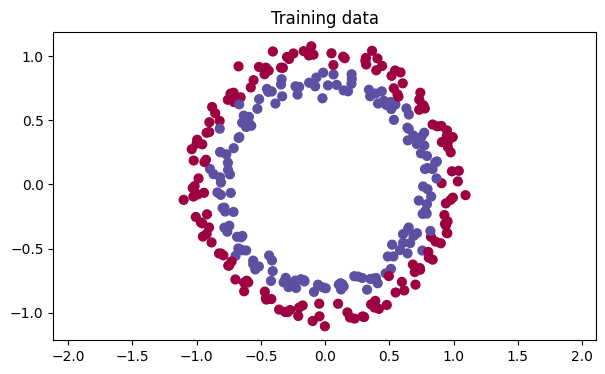

In [2]:
def make_circles(n_samples, noise, factor=0.8, seed=None):
    # Two concentric circles with Gaussian noise (NumPy-only version of a classic toy dataset).
    rng = np.random.RandomState(seed)
    n_out = n_samples // 2
    n_in = n_samples - n_out
    t_out = np.linspace(0, 2 * np.pi, n_out, endpoint=False)
    t_in = np.linspace(0, 2 * np.pi, n_in, endpoint=False)
    outer = np.stack([np.cos(t_out), np.sin(t_out)])            # radius 1
    inner = np.stack([np.cos(t_in), np.sin(t_in)]) * factor      # radius = factor
    X = np.hstack([outer, inner])
    Y = np.hstack([np.zeros(n_out), np.ones(n_in)]).reshape(1, -1)
    perm = rng.permutation(n_samples)                            # shuffle
    X, Y = X[:, perm], Y[:, perm]
    X = X + rng.normal(scale=noise, size=X.shape)
    return X, Y.astype(int)


def load_dataset():
    train_X, train_Y = make_circles(n_samples=300, noise=0.05, seed=1)
    test_X, test_Y = make_circles(n_samples=100, noise=0.05, seed=2)
    return train_X, train_Y, test_X, test_Y


train_X, train_Y, test_X, test_Y = load_dataset()
print("train_X shape:", train_X.shape, "  train_Y shape:", train_Y.shape)
print("test_X shape: ", test_X.shape, "  test_Y shape: ", test_Y.shape)

plt.scatter(train_X[0, :], train_X[1, :], c=train_Y.ravel(), s=40, cmap=plt.cm.Spectral)
plt.title("Training data")
plt.axis("equal")
plt.show()

<a name='3'></a>
## 3 - Helper Functions (provided)

These functions are already written for you. Read them so you know what the network does — you do **not** need to change them.

The network is: `LINEAR → RELU → LINEAR → RELU → LINEAR → SIGMOID`

| Function | What it does |
|---|---|
| `sigmoid`, `relu` | activation functions |
| `forward_propagation` | computes the prediction $a^{[3]}$ |
| `compute_loss` | binary cross-entropy cost |
| `backward_propagation` | computes the gradients |
| `update_parameters` | one gradient-descent step |
| `predict`, `predict_dec` | turn outputs into 0/1 labels and report accuracy |
| `plot_decision_boundary` | draws the regions the model labels 0 and 1 |

In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))   # clip avoids overflow warnings


def relu(x):
    return np.maximum(0, x)


def forward_propagation(X, parameters):
    W1, b1 = parameters["W1"], parameters["b1"]
    W2, b2 = parameters["W2"], parameters["b2"]
    W3, b3 = parameters["W3"], parameters["b3"]

    z1 = np.dot(W1, X) + b1
    a1 = relu(z1)
    z2 = np.dot(W2, a1) + b2
    a2 = relu(z2)
    z3 = np.dot(W3, a2) + b3
    a3 = sigmoid(z3)

    cache = (z1, a1, W1, b1, z2, a2, W2, b2, z3, a3, W3, b3)
    return a3, cache


def compute_loss(a3, Y):
    # Binary cross-entropy. a3 is clipped so that log(0) never happens.
    m = Y.shape[1]
    a3 = np.clip(a3, 1e-12, 1 - 1e-12)
    logprobs = Y * np.log(a3) + (1 - Y) * np.log(1 - a3)
    return float(-np.sum(logprobs) / m)


def backward_propagation(X, Y, cache):
    m = X.shape[1]
    (z1, a1, W1, b1, z2, a2, W2, b2, z3, a3, W3, b3) = cache

    dz3 = 1.0 / m * (a3 - Y)
    dW3 = np.dot(dz3, a2.T)
    db3 = np.sum(dz3, axis=1, keepdims=True)

    da2 = np.dot(W3.T, dz3)
    dz2 = da2 * (a2 > 0)
    dW2 = np.dot(dz2, a1.T)
    db2 = np.sum(dz2, axis=1, keepdims=True)

    da1 = np.dot(W2.T, dz2)
    dz1 = da1 * (a1 > 0)
    dW1 = np.dot(dz1, X.T)
    db1 = np.sum(dz1, axis=1, keepdims=True)

    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}


def update_parameters(parameters, grads, learning_rate):
    L = len(parameters) // 2
    for k in range(1, L + 1):
        parameters["W" + str(k)] = parameters["W" + str(k)] - learning_rate * grads["dW" + str(k)]
        parameters["b" + str(k)] = parameters["b" + str(k)] - learning_rate * grads["db" + str(k)]
    return parameters


def predict(X, y, parameters):
    a3, _ = forward_propagation(X, parameters)
    p = (a3 > 0.5).astype(int)
    print("Accuracy: " + str(np.mean(p == y)))
    return p


def predict_dec(parameters, X):
    a3, _ = forward_propagation(X, parameters)
    return (a3 > 0.5)


def plot_decision_boundary(model, X, y):
    x_min, x_max = X[0, :].min() - 1, X[0, :].max() + 1
    y_min, y_max = X[1, :].min() - 1, X[1, :].max() + 1
    h = 0.01
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = model(np.c_[xx.ravel(), yy.ravel()])
    Z = np.asarray(Z).reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral)
    plt.ylabel('x2')
    plt.xlabel('x1')
    plt.scatter(X[0, :], X[1, :], c=y.ravel(), cmap=plt.cm.Spectral)
    plt.show()

<a name='4'></a>
## 4 - The Model (provided)

`model()` builds a network with layer sizes `[2, 10, 5, 1]` and trains it with gradient descent. The argument `initialization` chooses which of **your** functions creates the starting weights:

- `initialization = "zeros"` → `initialize_parameters_zeros`
- `initialization = "random"` → `initialize_parameters_random`
- `initialization = "he"` → `initialize_parameters_he`

Read the code, then run the cell. (It will only be *used* after you write the three functions.)

In [4]:
def model(X, Y, learning_rate=0.01, num_iterations=15000, print_cost=True, initialization="he"):
    # Three-layer network: LINEAR->RELU->LINEAR->RELU->LINEAR->SIGMOID
    costs = []
    layers_dims = [X.shape[0], 10, 5, 1]

    if initialization == "zeros":
        parameters = initialize_parameters_zeros(layers_dims)
    elif initialization == "random":
        parameters = initialize_parameters_random(layers_dims)
    elif initialization == "he":
        parameters = initialize_parameters_he(layers_dims)

    for i in range(num_iterations):
        a3, cache = forward_propagation(X, parameters)
        cost = compute_loss(a3, Y)
        grads = backward_propagation(X, Y, cache)
        parameters = update_parameters(parameters, grads, learning_rate)

        if print_cost and i % 1000 == 0:
            print("Cost after iteration {}: {:.6f}".format(i, cost))
            costs.append(cost)

    plt.plot(np.arange(len(costs)) * 1000, costs)
    plt.ylabel('cost')
    plt.xlabel('iteration')
    plt.title("Initialization = '" + initialization + "', learning rate = " + str(learning_rate))
    plt.show()

    return parameters

<a name='5'></a>
## 5 - Zero Initialization

A network has two kinds of parameters:
- weight matrices $W^{[1]}, W^{[2]}, \dots, W^{[L]}$, where $W^{[l]}$ has shape $(n^{[l]}, n^{[l-1]})$
- bias vectors $b^{[1]}, b^{[2]}, \dots, b^{[L]}$, where $b^{[l]}$ has shape $(n^{[l]}, 1)$

Here $n^{[l]}$ = `layers_dims[l]` is the number of units in layer $l$.

### Exercise 1 - initialize_parameters_zeros

Set **all** weights and biases to zero. Use `np.zeros((rows, cols))` with the correct shapes. (You will see why this is a bad idea.)

In [5]:
def initialize_parameters_zeros(layers_dims):
    # Returns a dictionary {"W1", "b1", ..., "WL", "bL"} with every value set to 0.
    #   Wl has shape (layers_dims[l], layers_dims[l-1])
    #   bl has shape (layers_dims[l], 1)
    parameters = {}
    L = len(layers_dims)            # number of layers including the input layer

    for l in range(1, L):
        # (≈ 2 lines of code)
        # parameters['W' + str(l)] =
        # parameters['b' + str(l)] =
        # YOUR CODE STARTS HERE
        parameters['W' + str(l)] = np.zeros((layers_dims[l], layers_dims[l-1]))
        parameters['b' + str(l)] = np.zeros((layers_dims[l], 1))  

        # YOUR CODE ENDS HERE
    return parameters

**Test your function** — run the cell below.

In [6]:
def test_initialize_parameters_zeros(target):
    p = target([3, 2, 1])
    for key in ["W1", "b1", "W2", "b2"]:
        assert key in p, "Missing key '" + key + "'. Did you write your code in the function?"
    assert p["W1"].shape == (2, 3), "W1 has the wrong shape: " + str(p["W1"].shape)
    assert p["b1"].shape == (2, 1), "b1 has the wrong shape: " + str(p["b1"].shape)
    assert p["W2"].shape == (1, 2), "W2 has the wrong shape: " + str(p["W2"].shape)
    assert p["b2"].shape == (1, 1), "b2 has the wrong shape: " + str(p["b2"].shape)
    for key in p:
        assert np.all(p[key] == 0), key + " is not all zeros."
    p = target([4, 6, 3, 1])
    assert len(p) == 6, "For 4 layer sizes you should create 6 entries (W1..W3, b1..b3)."
    print("\033[92mAll tests passed.")


test_initialize_parameters_zeros(initialize_parameters_zeros)
parameters = initialize_parameters_zeros([3, 2, 1])
print("W1 = " + str(parameters["W1"]))
print("b1 = " + str(parameters["b1"]))
print("W2 = " + str(parameters["W2"]))
print("b2 = " + str(parameters["b2"]))

All tests passed.
W1 = [[0. 0. 0.]
 [0. 0. 0.]]
b1 = [[0.]
 [0.]]
W2 = [[0. 0.]]
b2 = [[0.]]


**Expected output**
```
All tests passed.
W1 = [[0. 0. 0.]
 [0. 0. 0.]]
b1 = [[0.]
 [0.]]
W2 = [[0. 0.]]
b2 = [[0.]]
```
Now train the model for 15,000 iterations with zeros initialization.

Cost after iteration 0: 0.693147
Cost after iteration 1000: 0.693147
Cost after iteration 2000: 0.693147
Cost after iteration 3000: 0.693147
Cost after iteration 4000: 0.693147
Cost after iteration 5000: 0.693147
Cost after iteration 6000: 0.693147
Cost after iteration 7000: 0.693147
Cost after iteration 8000: 0.693147
Cost after iteration 9000: 0.693147
Cost after iteration 10000: 0.693147
Cost after iteration 11000: 0.693147
Cost after iteration 12000: 0.693147
Cost after iteration 13000: 0.693147
Cost after iteration 14000: 0.693147


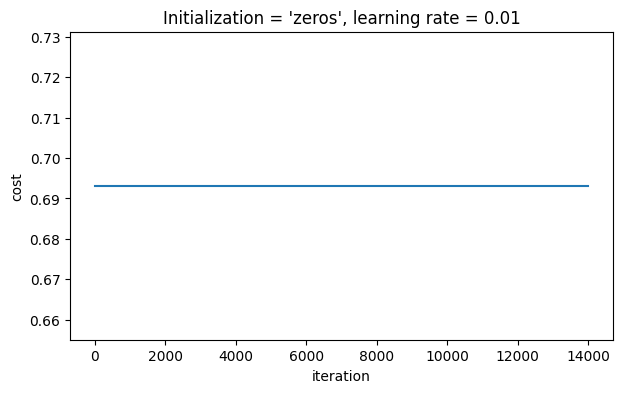

On the train set:
Accuracy: 0.5
On the test set:
Accuracy: 0.5


In [7]:
parameters = model(train_X, train_Y, initialization="zeros")
print("On the train set:")
predictions_train = predict(train_X, train_Y, parameters)
print("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

The cost does not go down and the accuracy is no better than guessing. Look at the predictions and the decision boundary:

predictions_train = [[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0]]
predictions_test = [[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]


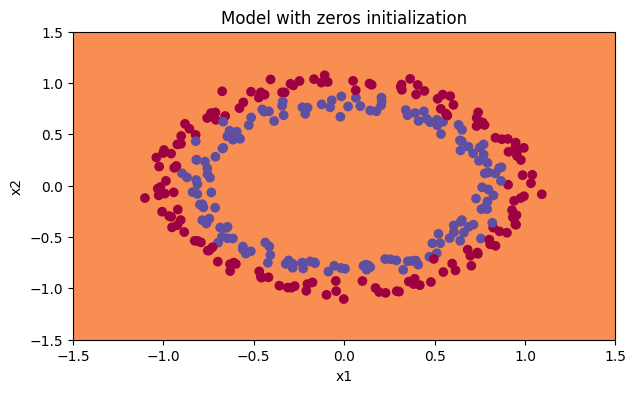

In [8]:
print("predictions_train = " + str(predictions_train))
print("predictions_test = " + str(predictions_test))

plt.title("Model with zeros initialization")
axes = plt.gca()
axes.set_xlim([-1.5, 1.5])
axes.set_ylim([-1.5, 1.5])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

### Why does zero initialization fail?

Follow one example through the network.

1. All weights and biases are 0, so every $z = Wx + b = 0$, and $a = \text{ReLU}(0) = 0$.
2. At the output, $\hat{y} = \sigma(0) = \tfrac{1}{2}$ for **every** input.
3. The loss is the same whatever the true label is:
   - if $y=1$: $\mathcal{L} = -\ln(0.5) \approx 0.6931$
   - if $y=0$: $\mathcal{L} = -\ln(1-0.5) \approx 0.6931$
4. Backpropagation multiplies by these zero weights and by $\text{ReLU}'(0)=0$, so the hidden-layer gradients are zero. The hidden weights never move.

More generally, when all weights in a layer start equal, every neuron in that layer computes the same thing and receives the same update. They stay identical forever — this is called **failing to break symmetry**. A layer with 10 identical neurons is no more powerful than a layer with 1 neuron, so the whole network behaves like a linear classifier (like logistic regression).

<font color='blue'>

**What you should remember:**
- Weights $W^{[l]}$ must be initialized **randomly** to break symmetry.
- Biases $b^{[l]}$ can be initialized to zero. Symmetry is still broken as long as $W^{[l]}$ is random.
</font>

<a name='6'></a>
## 6 - Large Random Initialization

To break symmetry, start the weights at random values. Each neuron then begins as a different function of its inputs and can learn something different. In this section the random values are deliberately **large**, to see what happens.

### Exercise 2 - initialize_parameters_random

- Weights: `np.random.randn(rows, cols) * 10`
- Biases: `np.zeros((rows, 1))`

The seed `np.random.seed(3)` is fixed so that everyone gets the same "random" numbers and the test can check them. Do not remove it.

In [9]:
def initialize_parameters_random(layers_dims):
    # Weights: standard normal * 10.  Biases: zeros.
    #   Wl has shape (layers_dims[l], layers_dims[l-1])
    #   bl has shape (layers_dims[l], 1)
    np.random.seed(3)               # keep this line: it makes the results reproducible
    parameters = {}
    L = len(layers_dims)

    for l in range(1, L):
        # (≈ 2 lines of code)
        # parameters['W' + str(l)] =
        # parameters['b' + str(l)] =
        # YOUR CODE STARTS HERE
        parameters['W' + str(l)] = np.random.randn(layers_dims[l], layers_dims[l-1]) * 10
        parameters['b' + str(l)] = np.zeros((layers_dims[l], 1))
    return parameters

**Test your function** — run the cell below.

In [10]:
def test_initialize_parameters_random(target):
    expected_W1 = np.array([[17.88628473, 4.36509851, 0.96497468], [-18.63492703, -2.77388203, -3.54758979]])
    expected_W2 = np.array([[-0.82741481, -6.27000677]])
    p = target([3, 2, 1])
    for key in ["W1", "b1", "W2", "b2"]:
        assert key in p, "Missing key '" + key + "'. Did you write your code in the function?"
    assert p["W1"].shape == (2, 3), "W1 has the wrong shape: " + str(p["W1"].shape)
    assert p["W2"].shape == (1, 2), "W2 has the wrong shape: " + str(p["W2"].shape)
    assert p["b1"].shape == (2, 1) and p["b2"].shape == (1, 1), "A bias vector has the wrong shape."
    assert np.all(p["b1"] == 0) and np.all(p["b2"] == 0), "Biases must be zeros."
    assert np.allclose(p["W1"], expected_W1), "W1 values are wrong. Did you use np.random.randn(...) * 10 and keep the seed?"
    assert np.allclose(p["W2"], expected_W2), "W2 values are wrong. Create W before b in each loop step."
    print("\033[92mAll tests passed.")


test_initialize_parameters_random(initialize_parameters_random)
parameters = initialize_parameters_random([3, 2, 1])
print("W1 = " + str(parameters["W1"]))
print("b1 = " + str(parameters["b1"]))
print("W2 = " + str(parameters["W2"]))
print("b2 = " + str(parameters["b2"]))

All tests passed.
W1 = [[ 17.88628473   4.36509851   0.96497468]
 [-18.63492703  -2.77388203  -3.54758979]]
b1 = [[0.]
 [0.]]
W2 = [[-0.82741481 -6.27000677]]
b2 = [[0.]]


**Expected output**
```
All tests passed.
W1 = [[ 17.88628473   4.36509851   0.96497468]
 [-18.63492703  -2.77388203  -3.54758979]]
b1 = [[0.]
 [0.]]
W2 = [[-0.82741481 -6.27000677]]
b2 = [[0.]]
```
Now train the model for 15,000 iterations with large random initialization.

Cost after iteration 0: 13.815522
Cost after iteration 1000: 0.621670
Cost after iteration 2000: 0.601374
Cost after iteration 3000: 0.573298
Cost after iteration 4000: 0.446847
Cost after iteration 5000: 0.408483
Cost after iteration 6000: 0.388791
Cost after iteration 7000: 0.380693
Cost after iteration 8000: 0.376961
Cost after iteration 9000: 0.374643
Cost after iteration 10000: 0.368399
Cost after iteration 11000: 0.365240
Cost after iteration 12000: 0.363536
Cost after iteration 13000: 0.362228
Cost after iteration 14000: 0.361277


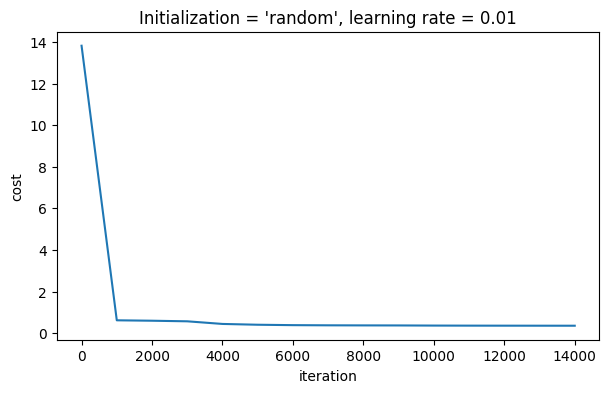

On the train set:
Accuracy: 0.8433333333333334
On the test set:
Accuracy: 0.82


In [11]:
parameters = model(train_X, train_Y, initialization="random")
print("On the train set:")
predictions_train = predict(train_X, train_Y, parameters)
print("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

Symmetry is broken, so the model no longer predicts the same label for everything. Look at the decision boundary:

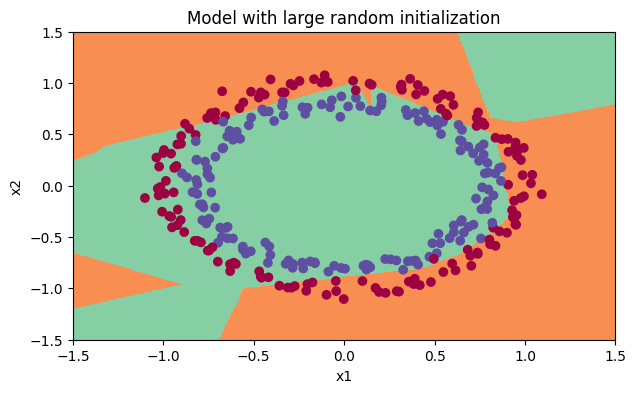

In [12]:
plt.title("Model with large random initialization")
axes = plt.gca()
axes.set_xlim([-1.5, 1.5])
axes.set_ylim([-1.5, 1.5])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

### Observations

1. **The cost starts very high.** With weights around ±10, the values of $z^{[3]}$ are huge, so the sigmoid outputs numbers extremely close to 0 or 1. When such a confident prediction is wrong, $\log(a^{[3]})$ is close to $\log(0)$ and the loss is enormous. (Our `compute_loss` clips $a^{[3]}$ to avoid an actual `inf`.)
2. **Training is slow.** A saturated sigmoid has an almost-zero slope, and large weights make activations and gradients badly scaled across layers (exploding / vanishing gradients). Optimization crawls.
3. Training longer would help, but a bad start wastes many iterations.

<font color='blue'>

**What you should remember:**
- Very large random weights do not work well.
- Small random weights work better. The question is: **how small?** That is what He initialization answers.
</font>

**Side note — `randn` vs `rand`:** `np.random.randn` draws from a normal (Gaussian) distribution centred on 0, so most weights are small and few are extreme. `np.random.rand` draws uniformly from $[0, 1)$, so every weight is positive — a poor choice for initialization.

<a name='7'></a>
## 7 - He Initialization

He initialization is named after the first author of *He et al., 2015*. It scales random normal weights by

$$\sqrt{\frac{2}{n^{[l-1]}}}$$

where $n^{[l-1]}$ = `layers_dims[l-1]` is the number of inputs to layer $l$.

**Why this number?** Each unit sums $n^{[l-1]}$ inputs, so its output variance grows with $n^{[l-1]}$. Dividing the weight variance by $n^{[l-1]}$ keeps activations at a stable size from layer to layer. The factor **2** compensates for ReLU, which sets about half of its inputs to zero.

For comparison, **Xavier initialization** uses $\sqrt{1/n^{[l-1]}}$ and is usually paired with `tanh` activations.

### Exercise 3 - initialize_parameters_he

Same as `initialize_parameters_random`, except multiply `np.random.randn(rows, cols)` by `np.sqrt(2 / layers_dims[l-1])` instead of 10. Biases are zeros.

Note: in this function `L` is the number of layers **excluding** the input layer, so the loop is `range(1, L + 1)`.

In [13]:
def initialize_parameters_he(layers_dims):
    # Weights: standard normal * sqrt(2 / layers_dims[l-1]).  Biases: zeros.
    #   Wl has shape (layers_dims[l], layers_dims[l-1])
    #   bl has shape (layers_dims[l], 1)
    np.random.seed(3)               # keep this line: it makes the results reproducible
    parameters = {}
    L = len(layers_dims) - 1        # number of layers excluding the input layer

    for l in range(1, L + 1):
        # (≈ 2 lines of code)
        # parameters['W' + str(l)] =
        # parameters['b' + str(l)] =
        # YOUR CODE STARTS HERE
        parameters['W' + str(l)] = np.random.randn(layers_dims[l], layers_dims[l-1]) * np.sqrt(2 / layers_dims[l-1])
        parameters['b' + str(l)] = np.zeros((layers_dims[l], 1))
    return parameters

**Test your function** — run the cell below.

In [14]:
def test_initialize_parameters_he(target):
    expected_W1 = np.array([[1.78862847, 0.43650985], [0.09649747, -1.8634927], [-0.2773882, -0.35475898], [-0.08274148, -0.62700068]])
    expected_W2 = np.array([[-0.03098412, -0.33744411, -0.92904268, 0.62552248]])
    p = target([2, 4, 1])
    for key in ["W1", "b1", "W2", "b2"]:
        assert key in p, "Missing key '" + key + "'. Did you write your code in the function?"
    assert p["W1"].shape == (4, 2), "W1 has the wrong shape: " + str(p["W1"].shape)
    assert p["W2"].shape == (1, 4), "W2 has the wrong shape: " + str(p["W2"].shape)
    assert p["b1"].shape == (4, 1) and p["b2"].shape == (1, 1), "A bias vector has the wrong shape."
    assert np.all(p["b1"] == 0) and np.all(p["b2"] == 0), "Biases must be zeros."
    assert np.allclose(p["W1"], expected_W1), "W1 values are wrong. Scale by np.sqrt(2 / layers_dims[l-1]) — the PREVIOUS layer."
    assert np.allclose(p["W2"], expected_W2), "W2 values are wrong. Scale by np.sqrt(2 / layers_dims[l-1]) — the PREVIOUS layer."
    print("\033[92mAll tests passed.")


test_initialize_parameters_he(initialize_parameters_he)
parameters = initialize_parameters_he([2, 4, 1])
print("W1 = " + str(parameters["W1"]))
print("b1 = " + str(parameters["b1"]))
print("W2 = " + str(parameters["W2"]))
print("b2 = " + str(parameters["b2"]))

All tests passed.
W1 = [[ 1.78862847  0.43650985]
 [ 0.09649747 -1.8634927 ]
 [-0.2773882  -0.35475898]
 [-0.08274148 -0.62700068]]
b1 = [[0.]
 [0.]
 [0.]
 [0.]]
W2 = [[-0.03098412 -0.33744411 -0.92904268  0.62552248]]
b2 = [[0.]]


**Expected output**
```
All tests passed.
W1 = [[ 1.78862847  0.43650985]
 [ 0.09649747 -1.8634927 ]
 [-0.2773882  -0.35475898]
 [-0.08274148 -0.62700068]]
b1 = [[0.]
 [0.]
 [0.]
 [0.]]
W2 = [[-0.03098412 -0.33744411 -0.92904268  0.62552248]]
b2 = [[0.]]
```
Now train the model for 15,000 iterations with He initialization.

Cost after iteration 0: 0.881689
Cost after iteration 1000: 0.688138
Cost after iteration 2000: 0.676679
Cost after iteration 3000: 0.656058
Cost after iteration 4000: 0.614985
Cost after iteration 5000: 0.542555
Cost after iteration 6000: 0.417005
Cost after iteration 7000: 0.298748
Cost after iteration 8000: 0.218451
Cost after iteration 9000: 0.167800
Cost after iteration 10000: 0.134633
Cost after iteration 11000: 0.111598
Cost after iteration 12000: 0.094538
Cost after iteration 13000: 0.082178
Cost after iteration 14000: 0.072517


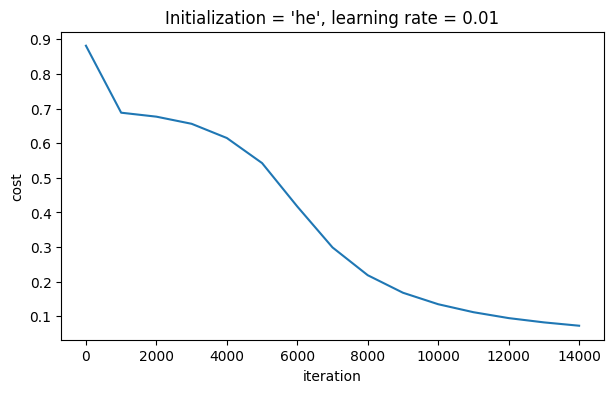

On the train set:
Accuracy: 0.99
On the test set:
Accuracy: 0.98


In [15]:
parameters = model(train_X, train_Y, initialization="he")
print("On the train set:")
predictions_train = predict(train_X, train_Y, parameters)
print("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

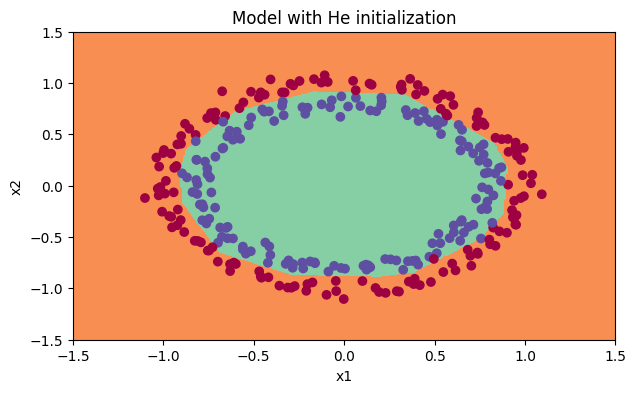

In [16]:
plt.title("Model with He initialization")
axes = plt.gca()
axes.set_xlim([-1.5, 1.5])
axes.set_ylim([-1.5, 1.5])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

**Observation:** with He initialization the model separates the red and blue points very well, using the same number of iterations and the same learning rate as before.

<a name='8'></a>
## 8 - Comparison and Conclusions

Run the cell below to train all three models once more (without printing) and compare them side by side.

Init         Train acc    Test acc
zeros           50.0%       50.0%
random          84.3%       82.0%
he              99.0%       98.0%


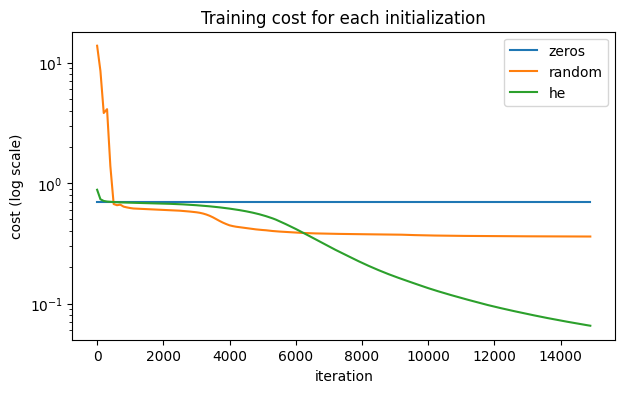

In [17]:
results = {}
for init in ["zeros", "random", "he"]:
    layers_dims = [train_X.shape[0], 10, 5, 1]
    p = {"zeros": initialize_parameters_zeros,
         "random": initialize_parameters_random,
         "he": initialize_parameters_he}[init](layers_dims)
    costs = []
    for i in range(15000):
        a3, cache = forward_propagation(train_X, p)
        if i % 100 == 0:
            costs.append(compute_loss(a3, train_Y))
        p = update_parameters(p, backward_propagation(train_X, train_Y, cache), 0.01)
    train_acc = np.mean(predict_dec(p, train_X) == train_Y)
    test_acc = np.mean(predict_dec(p, test_X) == test_Y)
    results[init] = (costs, train_acc, test_acc)

print("{:<10}{:>12}{:>12}".format("Init", "Train acc", "Test acc"))
for init, (_, tr, te) in results.items():
    print("{:<10}{:>11.1%}{:>12.1%}".format(init, tr, te))

for init, (costs, _, _) in results.items():
    plt.plot(np.arange(len(costs)) * 100, costs, label=init)
plt.yscale("log")
plt.xlabel("iteration")
plt.ylabel("cost (log scale)")
plt.title("Training cost for each initialization")
plt.legend()
plt.show()

Typical results (same iterations, same learning rate):

| Model | Train accuracy | Problem / Comment |
|---|---|---|
| 3-layer NN, zeros initialization | 50% | fails to break symmetry |
| 3-layer NN, large random initialization | ≈ 84% | weights too large |
| 3-layer NN, He initialization | 99% | recommended method |

<font color='blue'>

**Key takeaways:**
1. Different initializations lead to very different results.
2. Random initialization breaks symmetry, so different hidden units can learn different things.
3. Do not initialize weights to values that are too large.
4. He initialization works well for networks with ReLU activations.
</font>

<a name='9'></a>
## 9 - Questions to Answer

### Exercise 4 - Short answers

Write your answers in the Markdown cell below (2–4 sentences each).

1. In your own words, what does "breaking symmetry" mean, and why does zero initialization fail to do it?
2. Biases were initialized to zero in every method. Why is that acceptable for biases but not for weights?
3. Look at the cost at iteration 0 for the "random" model. Why is it so much larger than for the other two models?
4. He initialization uses $\sqrt{2/n^{[l-1]}}$. What would you expect if you used $\sqrt{2/n^{[l]}}$ (the *current* layer) instead? Try it and report what you see.
5. *(Bonus)* Change `* 10` in `initialize_parameters_random` to `* 0.01` and retrain. Compare the result with He initialization and explain the difference. (Change it back afterwards so the test still passes.)

**Your answers:**

**1.** Breaking symmetry means giving neurons different weights so they can learn different things. When we initialize all weights to zero, the neurons end up learning the same thing, which stops the model from learning properly.

**2.** It's okay to set biases to zero because the weights are already different, so the neurons can still learn different things. But if we set all the weights to zero, the neurons will behave the same way and won't learn different features.

**3.** The random model starts with a much higher cost because we multiplied the weights by 10, making them too large. This leads to very large outputs at the beginning, so the model starts with a higher error.

**4.** If we use the current layer instead of the previous layer, the weight values will be scaled differently. This might make the model learn slower or affect its accuracy because the weights could end up too large or too small. We would need to test it to see the actual difference.

**5. (Bonus)** If we change 10 to 0.01, the weights become very small, which can make learning slower. He initialization works better with ReLU because it keeps the values more balanced as they move through the layers, helping the model learn more effectively.

---
### Reference
K. He, X. Zhang, S. Ren, J. Sun, "Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification," *ICCV*, 2015.

*End of Lab 3.*